# ReviewIQ: adquisición y EDA

Fase B. Ejecutar todas las celdas descarga/verifica el origen fijado, audita las tres particiones y regenera informes y figuras. No se entrena ningún modelo. Los resultados publicados son agregados: no se muestran reseñas ni IDs.

Fuente: [SetFit/amazon_reviews_multi_es](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es). Uso académico según los [términos del corpus original](https://github.com/awslabs/open-data-docs/blob/main/docs/amazon-reviews-ml/README.md#license).

In [1]:
from pathlib import Path
import json
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "config.json").is_file() and (path / "ml").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from ml.data.eda import run_eda
summary = run_eda()
print("Revisión:", summary["revision"])
print("Semilla:", summary["seed"])
print("Particiones:", {split: info["rows"] for split, info in summary["audit"]["splits"].items()})

Revisión: 16015418b488c9186fce74b058877ea939ca934d
Semilla: 42
Particiones: {'train': 200000, 'validation': 5000, 'test': 5000}


## Calidad y balance

La validación falla ante columnas ausentes, nulos, vacíos o etiquetas inválidas. Los conteos de cero corresponden a una lectura completa validada. Las clases internas son 0–4; los gráficos muestran 1–5 estrellas.

{
  "train": {
    "rows": 200000,
    "label_counts": {
      "0": 40000,
      "1": 40000,
      "2": 40000,
      "3": 40000,
      "4": 40000
    },
    "class_proportions": {
      "0": 0.2,
      "1": 0.2,
      "2": 0.2,
      "3": 0.2,
      "4": 0.2
    },
    "null_empty_or_invalid_records": 0,
    "duplicate_id_rows": 0,
    "duplicate_exact_text_rows": 1736,
    "duplicate_normalized_text_rows": 1922,
    "normalized_text_groups_with_conflicting_labels": 427
  },
  "validation": {
    "rows": 5000,
    "label_counts": {
      "0": 1000,
      "1": 1000,
      "2": 1000,
      "3": 1000,
      "4": 1000
    },
    "class_proportions": {
      "0": 0.2,
      "1": 0.2,
      "2": 0.2,
      "3": 0.2,
      "4": 0.2
    },
    "null_empty_or_invalid_records": 0,
    "duplicate_id_rows": 0,
    "duplicate_exact_text_rows": 5,
    "duplicate_normalized_text_rows": 7,
    "normalized_text_groups_with_conflicting_labels": 1
  },
  "test": {
    "rows": 5000,
    "label_counts": {


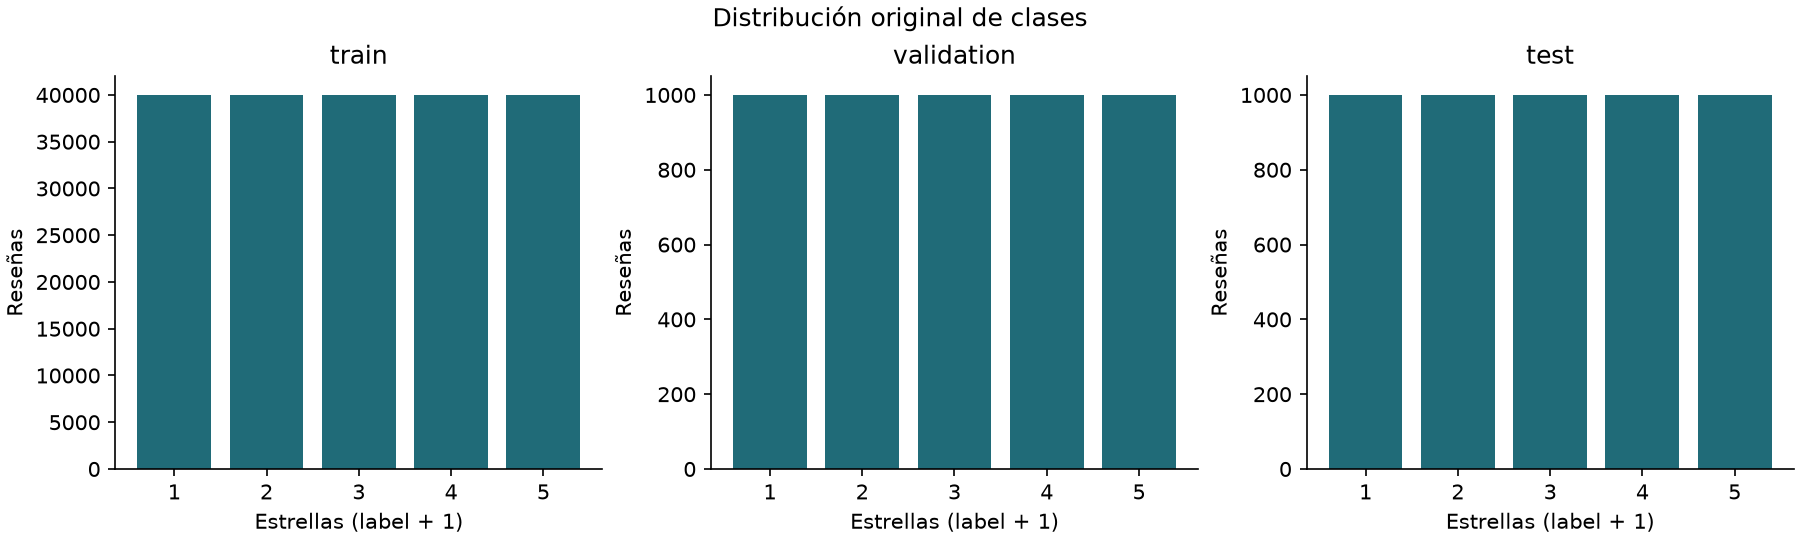

In [2]:
from IPython.display import display, Image
print(json.dumps(summary["audit"]["splits"], indent=2, ensure_ascii=False))
display(Image(filename=str(ROOT / "reports/figures/class_distribution.png")))

## Longitudes y rasgos descriptivos

Los tokens de EDA son secuencias alfabéticas Unicode sin eliminar stop words. La detección de emojis es aproximada. Las palabras frecuentes se calculan solo sobre train para no elegir vocabulario con los conjuntos reservados.

train {"characters": {"min": 16, "max": 3086, "mean": 151.3029, "p50": 120.0, "p90": 295.0, "p95": 391.0}, "word_tokens": {"min": 2, "max": 551, "mean": 27.6202, "p50": 22.0, "p90": 54.0, "p95": 71.0}, "text_features": {"numbers": {"rows": 32641, "proportion": 0.163205}, "urls": {"rows": 1, "proportion": 5e-06}, "accented_spanish_characters": {"rows": 143377, "proportion": 0.716885}, "emoji_heuristic": {"rows": 752, "proportion": 0.00376}}}
validation {"characters": {"min": 19, "max": 1576, "mean": 150.2334, "p50": 121.0, "p90": 290.0, "p95": 371.0}, "word_tokens": {"min": 2, "max": 257, "mean": 27.3952, "p50": 22.0, "p90": 52.0, "p95": 68.0}, "text_features": {"numbers": {"rows": 824, "proportion": 0.1648}, "urls": {"rows": 0, "proportion": 0.0}, "accented_spanish_characters": {"rows": 3558, "proportion": 0.7116}, "emoji_heuristic": {"rows": 18, "proportion": 0.0036}}}
test {"characters": {"min": 20, "max": 1789, "mean": 151.9142, "p50": 122.0, "p90": 290.0, "p95": 382.0}, "word_token

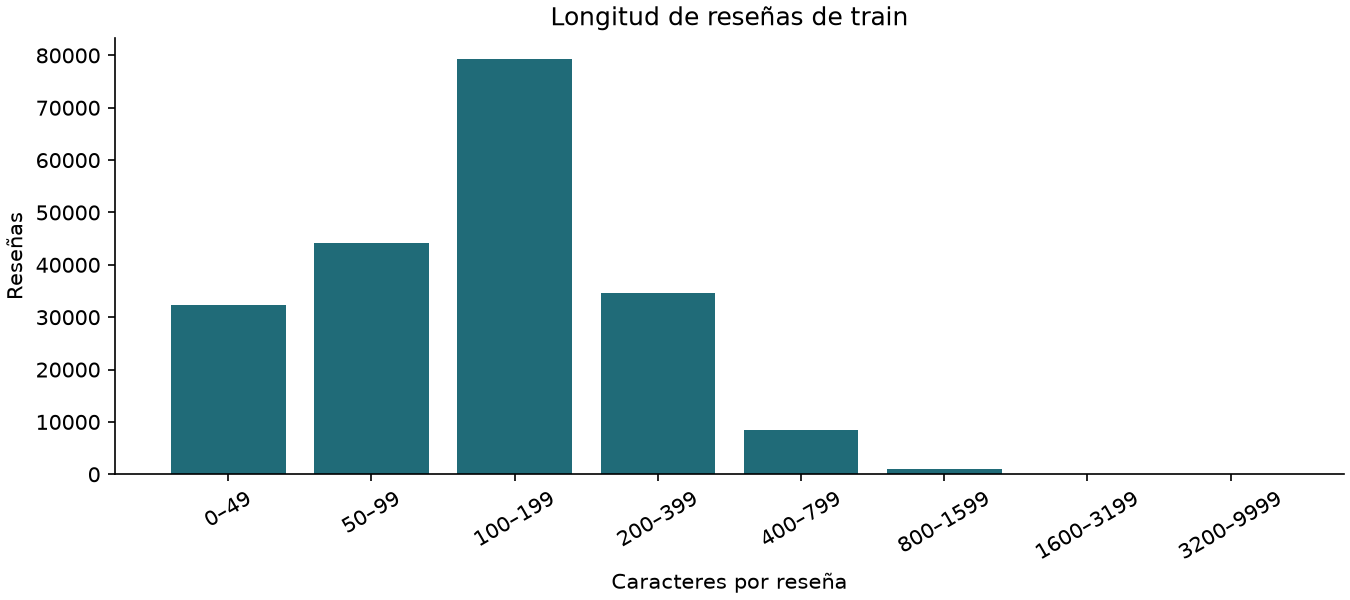

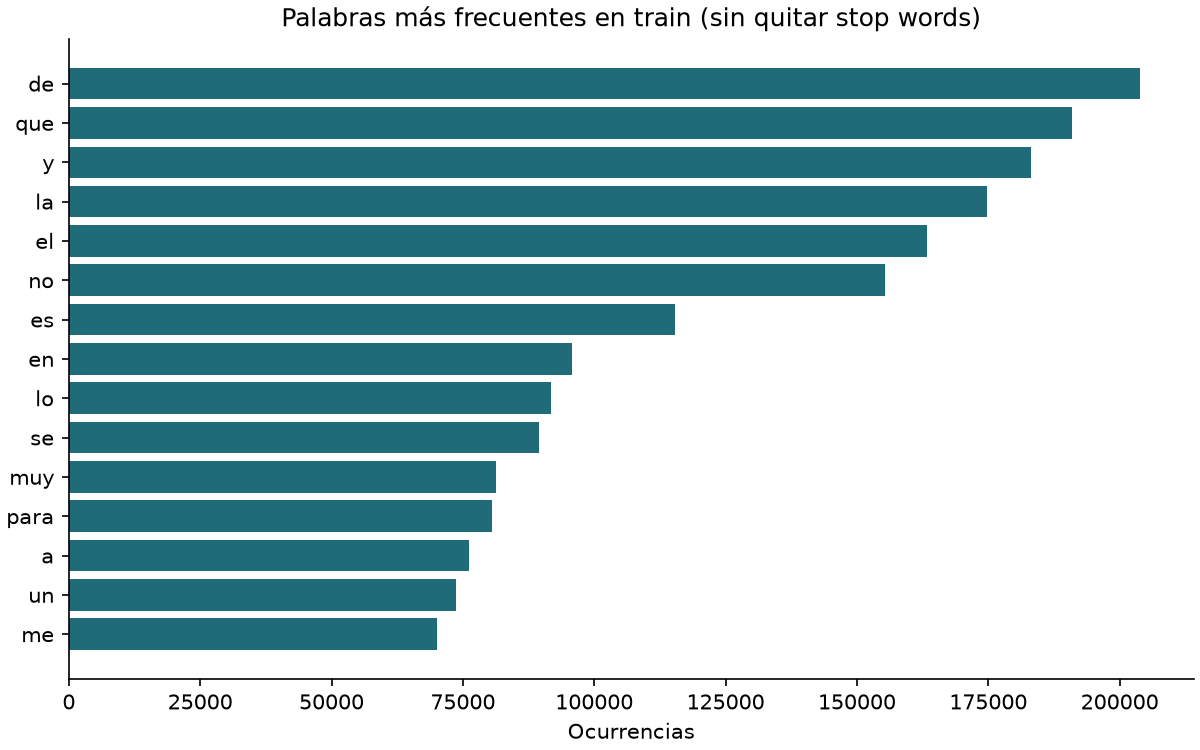

In [3]:
for split, statistics in summary["statistics"].items():
    print(split, json.dumps({key: statistics[key] for key in ("characters", "word_tokens", "text_features")}, ensure_ascii=False))
display(Image(filename=str(ROOT / "reports/figures/train_lengths.png")))
display(Image(filename=str(ROOT / "reports/figures/train_frequent_words.png")))

In [4]:
print(json.dumps(summary["statistics"]["train"]["frequent_words_by_label"], indent=2, ensure_ascii=False))

{
  "0": [
    {
      "word": "no",
      "count": 47970
    },
    {
      "word": "de",
      "count": 42401
    },
    {
      "word": "que",
      "count": 38723
    },
    {
      "word": "el",
      "count": 36634
    },
    {
      "word": "y",
      "count": 36491
    },
    {
      "word": "la",
      "count": 35182
    },
    {
      "word": "me",
      "count": 20274
    },
    {
      "word": "se",
      "count": 20074
    },
    {
      "word": "lo",
      "count": 19990
    },
    {
      "word": "en",
      "count": 19218
    },
    {
      "word": "a",
      "count": 17616
    },
    {
      "word": "es",
      "count": 17213
    },
    {
      "word": "un",
      "count": 13587
    },
    {
      "word": "para",
      "count": 11995
    },
    {
      "word": "con",
      "count": 11970
    },
    {
      "word": "una",
      "count": 10470
    },
    {
      "word": "por",
      "count": 9985
    },
    {
      "word": "los",
      "count": 9665
    },
    {
      "w

## Duplicados, solapamientos y preparación

Se comparan IDs y textos exactos o con casefold y espacios colapsados. Se excluyen de train los textos/IDs presentes en validation o test, los grupos de texto con etiquetas contradictorias y duplicados internos. Validation y test conservan filas, orden, texto y etiquetas; se descarta la columna auxiliar label_text. Los duplicados entre ambos conjuntos reservados se documentan sin modificar los splits.

In [5]:
print(json.dumps(summary["audit"]["overlaps"], indent=2, ensure_ascii=False))
print(json.dumps(summary["preparation"], indent=2, ensure_ascii=False))

{
  "train__validation": {
    "shared_ids": 0,
    "shared_exact_texts": 66,
    "shared_normalized_texts": 75,
    "train_rows_with_shared_text": 427,
    "validation_rows_with_shared_text": 82
  },
  "train__test": {
    "shared_ids": 0,
    "shared_exact_texts": 57,
    "shared_normalized_texts": 61,
    "train_rows_with_shared_text": 483,
    "test_rows_with_shared_text": 67
  },
  "validation__test": {
    "shared_ids": 0,
    "shared_exact_texts": 9,
    "shared_normalized_texts": 9,
    "validation_rows_with_shared_text": 15,
    "test_rows_with_shared_text": 12
  }
}
{
  "policy": "Remove train overlaps with either holdout, all train text groups with conflicting labels, then keep first train ID/text. Preserve holdout rows, order, text and labels; drop only unused columns.",
  "columns": [
    "id",
    "text",
    "label"
  ],
  "splits": {
    "train": {
      "source_rows": 200000,
      "prepared_rows": 197572,
      "removed_rows_by_reason": {
        "conflicting_labels_f

## Próxima fase

Implementar y comparar las variantes NLP sobre train preparado. La futura validación cruzada será estratificada, con semilla 42 y solo train; test queda reservado para la evaluación final. No se han medido accuracy ni F1 en esta fase. Consultar [documentación del dataset](../docs/DATASET.md).